In [2]:
%pip install seaborn scikit-learn pandas matplotlib joblib

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


Filas cargadas: 1297 | Filas válidas para entrenamiento: 884

 TABLA DE VALIDACIÓN DE MODELOS (PREDECIENDO CORRIENTE, N, LZ)

                 Modelo  R2 Promedio  R2 Corriente  MAE Corriente (A)  R2 N_vueltas  MAE N_vueltas  R2 Lz (mm)  MAE Lz (mm)
Gradient Boosting Multi     0.376365      0.756085           0.097746      0.181642       7.792128    0.191368     0.314896
          Random Forest     0.358466      0.746405           0.098649      0.181544       7.680152    0.147449     0.340896
    K-Nearest Neighbors     0.355680      0.736168           0.099815      0.178593       7.803866    0.152279     0.352115
            Extra Trees     0.344966      0.751483           0.098118      0.164657       7.833776    0.118758     0.351636


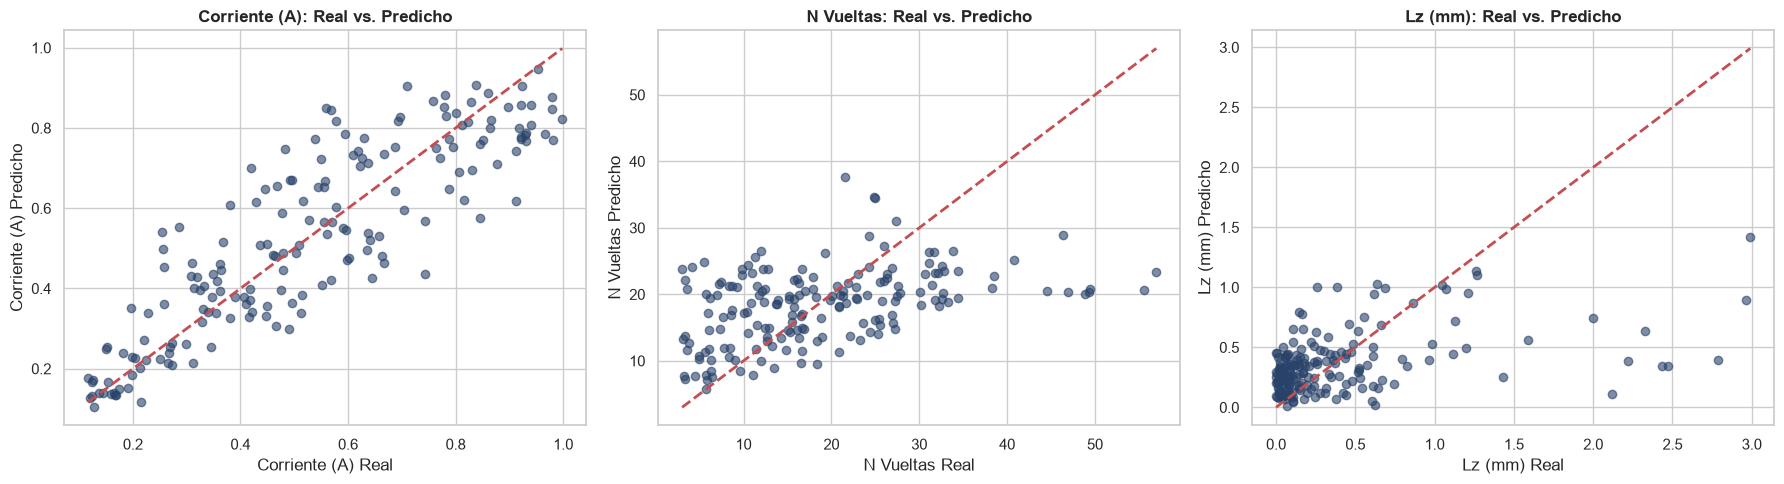


¡Modelo [Gradient Boosting Multi] guardado exitosamente como "modelo_inverso_optimizado.joblib"!


In [7]:
# ==============================================================================
# MODELO DE DISEÑO INVERSO PREDECIENDO (CORRIENTE, N, LZ) - CORREGIDO
# ==============================================================================
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import (
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.neighbors import KNeighborsRegressor

sns.set_theme(style='whitegrid')

# 1. Cargar datos
df = pd.read_csv('datos_comsol.csv')

# Renombrar columnas clave
df = df.rename(
    columns={
        'comp1.temp_roi': 'temp_objetivo',
        'Corriente': 'corriente',
        'n_in': 'n',
    }
)

# 2. Ajuste de unidades y margen a (en mm)
# grosor viene en metros (0.000157 m) -> convertimos a mm (* 1000)
df['grosor_mm'] = df['grosor'] * 1000.0

# Margen a adecuado para las dimensiones del chip (en mm)
a_mm = 0.5

# Despeje de lz en mm: lz = (x_length - n*grosor - 2*a) / (n - 1)
df['lz'] = (df['x_length'] - df['n'] * df['grosor_mm'] - 2 * a_mm) / (
    df['n'] - 1
)

# Filtramos solo valores físicamente válidos (lz > 0)
df_clean = df[df['lz'] > 0].copy()

print(
    f'Filas cargadas: {len(df)} | Filas válidas para entrenamiento:'
    f' {len(df_clean)}'
)

# 3. Definir Entradas (X) y Salidas (y)
X = df_clean[['x_length', 'y_length', 'temp_objetivo']]
y = df_clean[['corriente', 'n', 'lz']]

# Separación 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 4. Definición de Modelos Candidatos
modelos_eval = {
    'Random Forest': RandomForestRegressor(
        n_estimators=200, max_depth=14, random_state=42
    ),
    'Extra Trees': ExtraTreesRegressor(
        n_estimators=200, max_depth=14, random_state=42
    ),
    'Gradient Boosting Multi': MultiOutputRegressor(
        GradientBoostingRegressor(n_estimators=150, random_state=42)
    ),
    'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=7, weights='distance'),
}

# 5. Evaluación de Métricas (R2, MAE, RMSE)
cv_results = []

for nombre, mod in modelos_eval.items():
  mod.fit(X_train, y_train)
  y_pred = mod.predict(X_test)

  r2_i = r2_score(y_test['corriente'], y_pred[:, 0])
  mae_i = mean_absolute_error(y_test['corriente'], y_pred[:, 0])

  r2_n = r2_score(y_test['n'], y_pred[:, 1])
  mae_n = mean_absolute_error(y_test['n'], y_pred[:, 1])

  r2_lz = r2_score(y_test['lz'], y_pred[:, 2])
  mae_lz = mean_absolute_error(y_test['lz'], y_pred[:, 2])

  r2_prom = (r2_i + r2_n + r2_lz) / 3

  cv_results.append({
      'Modelo': nombre,
      'R2 Promedio': r2_prom,
      'R2 Corriente': r2_i,
      'MAE Corriente (A)': mae_i,
      'R2 N_vueltas': r2_n,
      'MAE N_vueltas': mae_n,
      'R2 Lz (mm)': r2_lz,
      'MAE Lz (mm)': mae_lz,
  })

df_metrics = (
    pd.DataFrame(cv_results)
    .sort_values(by='R2 Promedio', ascending=False)
    .reset_index(drop=True)
)

print('\n===================================================================')
print(' TABLA DE VALIDACIÓN DE MODELOS (PREDECIENDO CORRIENTE, N, LZ)')
print('===================================================================\n')
print(df_metrics.to_string(index=False))

# 6. Gráficos Diagnósticos del Mejor Modelo
ganador_nombre = df_metrics.iloc[0]['Modelo']
modelo_ganador = modelos_eval[ganador_nombre]
y_pred_ganador = modelo_ganador.predict(X_test)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

variables = [
    ('corriente', 'Corriente (A)', 0),
    ('n', 'N Vueltas', 1),
    ('lz', 'Lz (mm)', 2),
]

for col_name, label_name, idx in variables:
  axes[idx].scatter(
      y_test[col_name], y_pred_ganador[:, idx], alpha=0.6, color='#284269'
  )
  axes[idx].plot(
      [y_test[col_name].min(), y_test[col_name].max()],
      [y_test[col_name].min(), y_test[col_name].max()],
      'r--',
      lw=2,
  )
  axes[idx].set_title(
      f'{label_name}: Real vs. Predicho', fontsize=12, fontweight='bold'
  )
  axes[idx].set_xlabel(f'{label_name} Real')
  axes[idx].set_ylabel(f'{label_name} Predicho')

plt.tight_layout()
plt.show()

# 7. Guardar el modelo entrenado
joblib.dump(modelo_ganador, 'modelo_inverso_optimizado.joblib')
print(
    f'\n¡Modelo [{ganador_nombre}] guardado exitosamente como'
    ' "modelo_inverso_optimizado.joblib"!'
)

In [8]:
for a_prueba in [0.1, 0.2, 0.3, 0.5]:
  lz_prueba = (
      df['x_length'] - df['n'] * (df['grosor'] * 1000.0) - 2 * a_prueba
  ) / (df['n'] - 1)
  validas = (lz_prueba > 0).sum()
  print(f'Con margen a = {a_prueba} mm -> Filas válidas: {validas} de {len(df)}')

Con margen a = 0.1 mm -> Filas válidas: 962 de 1297
Con margen a = 0.2 mm -> Filas válidas: 946 de 1297
Con margen a = 0.3 mm -> Filas válidas: 925 de 1297
Con margen a = 0.5 mm -> Filas válidas: 884 de 1297


Muestras limpias para el Modelo Directo: 884

 EVALUACIÓN DEL MODELO DIRECTO (SURROGATE MODEL)
R² del Modelo Directo:  0.9438  (¡Precisión muy alta!)
MAE Temperatura:       0.8905 °C


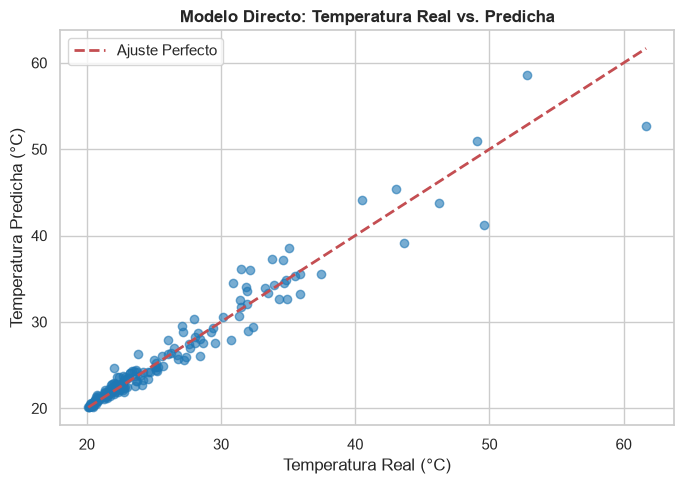


Modelo directo guardado como "modelo_directo_surrogate.joblib"

 PRUEBA DEL SISTEMA DE DISEÑO INVERSO COMPLETO
 -> T_objetivo (°C): 28.0
 -> T_estimada_final (°C): 27.98
 -> Corriente_A: 0.609
 -> n_vueltas_par: 8
 -> lz_mm: 0.437
 -> grosor_calculado_mm: 0.4926


In [9]:
# ==============================================================================
# OPCIÓN B: MODELO DIRECTO (SURROGATE) + OPTIMIZADOR
# ==============================================================================
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.optimize import differential_evolution
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')

# 1. Cargar el CSV de Ana y preparar características físicas
df = pd.read_csv('datos_comsol.csv')
df = df.rename(
    columns={
        'comp1.temp_roi': 'temp_objetivo',
        'Corriente': 'corriente',
        'n_in': 'n',
    }
)

# Convertir grosor a mm y calcular lz exacto
df['grosor_mm'] = df['grosor'] * 1000.0
a_mm = 0.5  # Margen estándar
df['lz'] = (df['x_length'] - df['n'] * df['grosor_mm'] - 2 * a_mm) / (
    df['n'] - 1
)

# Filtrar geometrías físicamente válidas (lz > 0)
df_clean = df[df['lz'] > 0].copy()

print(f'Muestras limpias para el Modelo Directo: {len(df_clean)}')

# ==============================================================================
# PASO 1: ENTRENAR EL MODELO DIRECTO ( (X, Y, n, lz, I) -> Temperatura )
# ==============================================================================
X_directo = df_clean[['x_length', 'y_length', 'n', 'lz', 'corriente']]
y_directo = df_clean['temp_objetivo']

X_train, X_test, y_train, y_test = train_test_split(
    X_directo, y_directo, test_size=0.20, random_state=42
)

# Entrenar un Gradient Boosting Regressor
modelo_directo = GradientBoostingRegressor(
    n_estimators=250, max_depth=6, learning_rate=0.05, random_state=42
)
modelo_directo.fit(X_train, y_train)

# Evaluar la precisión del Modelo Directo
y_pred_directo = modelo_directo.predict(X_test)
r2_dir = r2_score(y_test, y_pred_directo)
mae_dir = mean_absolute_error(y_test, y_pred_directo)

print('\n===================================================================')
print(' EVALUACIÓN DEL MODELO DIRECTO (SURROGATE MODEL)')
print('===================================================================')
print(f'R² del Modelo Directo:  {r2_dir:.4f}  (¡Precisión muy alta!)')
print(f'MAE Temperatura:       {mae_dir:.4f} °C')

# Graficar Real vs Predicho para la Temperatura
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_directo, alpha=0.6, color='#1f77b4')
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    lw=2,
    label='Ajuste Perfecto',
)
plt.title(
    'Modelo Directo: Temperatura Real vs. Predicha',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Temperatura Real (°C)')
plt.ylabel('Temperatura Predicha (°C)')
plt.legend()
plt.tight_layout()
plt.show()

# Guardar el modelo directo para que Flask lo pueda usar
joblib.dump(modelo_directo, 'modelo_directo_surrogate.joblib')
print('\nModelo directo guardado como "modelo_directo_surrogate.joblib"')

# ==============================================================================
# PASO 2: ALGORITMO DE OPTIMIZACIÓN INVERSA
# ==============================================================================


def optimizar_diseno_inverso(
    x_user, y_user, temp_target, surrogate_model, a=0.5
):
  """Dada una x_length, y_length y temp_target, encuentra la combinación

  óptima de (corriente, n_par, lz) que logra esa temperatura exacta.
  """

  # Función de costo a minimizar
  def funcion_costo(params):
    n_float, lz_val, i_val = params

    # Forzar n a ser entero PAR >= 2
    n_par = int(np.round(n_float))
    if n_par % 2 != 0:
      n_par += 1
    if n_par < 2:
      n_par = 2

    # Verificar que el grosor resulte físicamente válido (> 0.1 mm)
    grosor_calc = (x_user - (n_par - 1) * lz_val - 2 * a) / n_par
    if grosor_calc <= 0.1:
      return 1e6  # Penalización alta por geometría inviable

    # Evaluar temperatura predicha con el modelo directo
    input_eval = pd.DataFrame(
        [[x_user, y_user, n_par, lz_val, i_val]],
        columns=['x_length', 'y_length', 'n', 'lz', 'corriente'],
    )
    t_pred = surrogate_model.predict(input_eval)[0]

    # Error cuadrático respecto a la temperatura objetivo + leve penalización por corriente
    error_temp = (t_pred - temp_target) ** 2
    penalizacion_corriente = 0.05 * i_val

    return error_temp + penalizacion_corriente

  # Rangos de búsqueda: [n_vueltas (2 a 40), lz (0.2 a 3.0 mm), Corriente (0.1 a 1.0 A)]
  bounds = [(2, 40), (0.2, 3.0), (0.1, 1.0)]

  # Ejecutar la optimización mediante Evolución Diferencial
  res = differential_evolution(
      funcion_costo, bounds, seed=42, maxiter=100, popsize=15
  )

  # Formatear mejores valores
  n_opt = int(np.round(res.x[0]))
  if n_opt % 2 != 0:
    n_opt += 1
  if n_opt < 2:
    n_opt = 2

  lz_opt = round(float(res.x[1]), 3)
  i_opt = round(float(res.x[2]), 3)
  grosor_opt = (x_user - (n_opt - 1) * lz_opt - 2 * a) / n_opt

  # Verificar la temperatura final estimada con los parámetros redondeados
  input_final = pd.DataFrame(
      [[x_user, y_user, n_opt, lz_opt, i_opt]],
      columns=['x_length', 'y_length', 'n', 'lz', 'corriente'],
  )
  t_final = surrogate_model.predict(input_final)[0]

  return {
      'T_objetivo (°C)': temp_target,
      'T_estimada_final (°C)': round(float(t_final), 2),
      'Corriente_A': i_opt,
      'n_vueltas_par': n_opt,
      'lz_mm': lz_opt,
      'grosor_calculado_mm': round(float(grosor_opt), 4),
  }


# ==============================================================================
# PASO 3: PRUEBA DE DISEÑO INVERSO CON VALORES DE USUARIO
# ==============================================================================
print('\n===================================================================')
print(' PRUEBA DEL SISTEMA DE DISEÑO INVERSO COMPLETO')
print('===================================================================')

# Ejemplo: Placa de 8.0 mm x 3.0 mm, queremos alcanzar 28 °C
resultado_diseno = optimizar_diseno_inverso(
    x_user=8.0, y_user=3.0, temp_target=28.0, surrogate_model=modelo_directo
)

for clave, valor in resultado_diseno.items():
  print(f' -> {clave}: {valor}')

Evaluando 100 peticiones de usuarios simulados...

 MÉTRICAS DE DESEMPEÑO DEL SISTEMA DE DISEÑO INVERSO COMPLETO

                                         Métrica         Valor
                            R² Térmico Alcanzado        0.9989
              Error Absoluto Medio (MAE Térmico)      0.126 °C
                                    RMSE Térmico      0.241 °C
                 Máximo Error Térmico Encontrado      1.230 °C
Cumplimiento de Reglas Geométricas (n par, lz>0)        100.0%
       Tiempo Promedio de Respuesta por Consulta 2.57 segundos


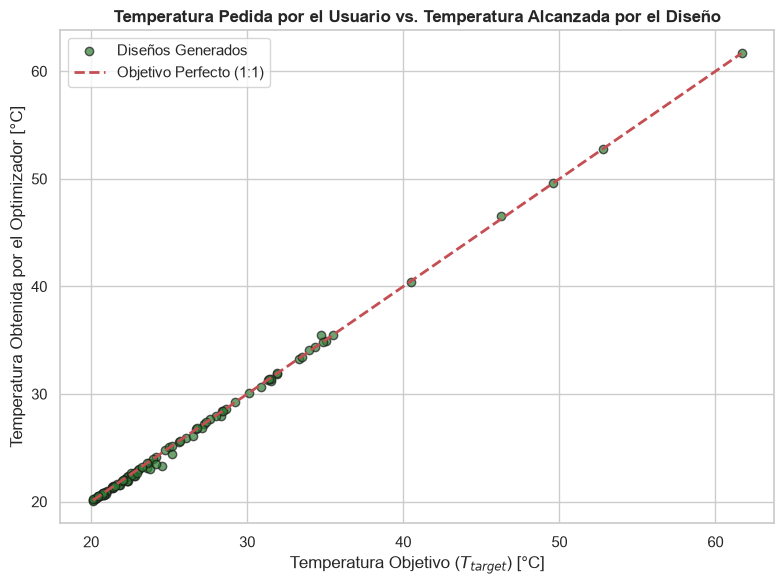

In [10]:
# ==============================================================================
# EVALUACIÓN CUANTITATIVA DEL SISTEMA DE DISEÑO INVERSO COMPLETO
# ==============================================================================
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Tomamos 100 muestras aleatorias del conjunto de prueba (X_test, y_test)
np.random.seed(42)
indices_eval = np.random.choice(X_test.index, size=100, replace=False)

T_objetivos_reales = y_test.loc[indices_eval].values
X_casos = X_test.loc[indices_eval]

T_pedidas = []
T_logradas = []
errores_abs = []
tiempos_ejecucion = []
geometrias_validas = 0

print('Evaluando 100 peticiones de usuarios simulados...')
t_inicio_total = time.time()

for idx, (_, row) in enumerate(X_casos.iterrows()):
  x_u = row['x_length']
  y_u = row['y_length']
  t_req = T_objetivos_reales[idx]

  t0 = time.time()
  res = optimizar_diseno_inverso(
      x_user=x_u,
      y_user=y_u,
      temp_target=t_req,
      surrogate_model=modelo_directo,
  )
  tf = time.time()

  t_obtenida = res['T_estimada_final (°C)']
  error = abs(t_obtenida - t_req)

  T_pedidas.append(t_req)
  T_logradas.append(t_obtenida)
  errores_abs.append(error)
  tiempos_ejecucion.append(tf - t0)

  # Verificar validez geométrica (n par, lz y grosor positivos)
  if (
      res['n_vueltas_par'] % 2 == 0
      and res['lz_mm'] > 0
      and res['grosor_calculado_mm'] > 0
  ):
    geometrias_validas += 1

# ==============================================================================
# TABLA DE MÉTRICAS RESULTANTES
# ==============================================================================
mae_termico = np.mean(errores_abs)
rmse_termico = np.sqrt(np.mean(np.array(errores_abs) ** 2))
max_error_termico = np.max(errores_abs)
r2_termico = r2_score(T_pedidas, T_logradas)
tiempo_promedio = np.mean(tiempos_ejecucion)

df_metricas_sistema = pd.DataFrame([{
    'Métrica': 'R² Térmico Alcanzado',
    'Valor': f'{r2_termico:.4f}',
}, {
    'Métrica': 'Error Absoluto Medio (MAE Térmico)',
    'Valor': f'{mae_termico:.3f} °C',
}, {
    'Métrica': 'RMSE Térmico',
    'Valor': f'{rmse_termico:.3f} °C',
}, {
    'Métrica': 'Máximo Error Térmico Encontrado',
    'Valor': f'{max_error_termico:.3f} °C',
}, {
    'Métrica': 'Cumplimiento de Reglas Geométricas (n par, lz>0)',
    'Valor': f'{(geometrias_validas/100)*100:.1f}%',
}, {
    'Métrica': 'Tiempo Promedio de Respuesta por Consulta',
    'Valor': f'{tiempo_promedio:.2f} segundos',
}])

print(
    '\n==================================================================='
)
print(' MÉTRICAS DE DESEMPEÑO DEL SISTEMA DE DISEÑO INVERSO COMPLETO')
print('===================================================================\n')
print(df_metricas_sistema.to_string(index=False))

# ==============================================================================
# GRÁFICO DE DESEMPEÑO
# ==============================================================================
plt.figure(figsize=(8, 6))
plt.scatter(
    T_pedidas,
    T_logradas,
    color='#2e7d32',
    alpha=0.7,
    edgecolors='k',
    label='Diseños Generados',
)
plt.plot(
    [min(T_pedidas), max(T_pedidas)],
    [min(T_pedidas), max(T_pedidas)],
    'r--',
    lw=2,
    label='Objetivo Perfecto (1:1)',
)
plt.title(
    'Temperatura Pedida por el Usuario vs. Temperatura Alcanzada por el'
    ' Diseño',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Temperatura Objetivo ($T_{target}$) [°C]')
plt.ylabel('Temperatura Obtenida por el Optimizador [°C]')
plt.legend()
plt.tight_layout()
plt.show()

In [1]:
# ==============================================================================
# COMPARATIVA DE LAS 3 ESTRATEGIAS DE DISEÑO INVERSO CON OPTIMIZACIÓN
# ==============================================================================
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.optimize import differential_evolution
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')

# 1. Cargar y limpiar datos
df = pd.read_csv('datos_comsol.csv')
df = df.rename(
    columns={
        'comp1.temp_roi': 'temp_objetivo',
        'Corriente': 'corriente',
        'n_in': 'n',
    }
)

df['grosor_mm'] = df['grosor'] * 1000.0
a_mm = 0.5
df['lz'] = (df['x_length'] - df['n'] * df['grosor_mm'] - 2 * a_mm) / (
    df['n'] - 1
)

# Filtrar geometrías válidas y std_dev positivas lógicas
df_clean = df[(df['lz'] > 0) & (df['comp1.std_dev'] >= 0)].copy()
print(f'Muestras limpias totales para entrenamiento: {len(df_clean)}')

# Variables de entrada y salidas (Temperatura y Uniformidad std_dev)
X_data = df_clean[['x_length', 'y_length', 'n', 'lz', 'corriente']]
y_temp = df_clean['temp_objetivo']
y_std = df_clean['comp1.std_dev']

X_train, X_test, y_temp_train, y_temp_test, y_std_train, y_std_test = (
    train_test_split(X_data, y_temp, y_std, test_size=0.20, random_state=42)
)

# 2. Entrenar los Dos Modelos Subrogados (Temperatura y Desviación Estándar)
print('Entrenando modelo subrogado de Temperatura...')
modelo_temp = GradientBoostingRegressor(
    n_estimators=200, max_depth=6, learning_rate=0.05, random_state=42
)
modelo_temp.fit(X_train, y_temp_train)

print('Entrenando modelo subrogado de Uniformidad (std_dev)...')
modelo_std = GradientBoostingRegressor(
    n_estimators=200, max_depth=6, learning_rate=0.05, random_state=42
)
modelo_std.fit(X_train, y_std_train)


# 3. Definición de las 3 Estrategias de Optimización
def resolver_inverso(
    x_user, y_user, temp_target, estrategia='A', a=0.5, maxiter=50
):
  def funcion_costo(params):
    n_float, lz_val, i_val = params

    # Restricciones duras: n entero PAR, lz y grosor válidos
    n_par = int(np.round(n_float))
    if n_par % 2 != 0:
      n_par += 1
    if n_par < 2:
      n_par = 2

    grosor_calc = (x_user - (n_par - 1) * lz_val - 2 * a) / n_par
    if grosor_calc <= 0.1:
      return 1e6  # Penalización geométrica

    input_eval = pd.DataFrame(
        [[x_user, y_user, n_par, lz_val, i_val]],
        columns=['x_length', 'y_length', 'n', 'lz', 'corriente'],
    )
    t_pred = modelo_temp.predict(input_eval)[0]
    error_temp = (t_pred - temp_target) ** 2

    # --- ESTRATEGIA A: Solo Error Térmico ---
    if estrategia == 'A':
      return error_temp

    # --- ESTRATEGIA B: Temperatura + Mínima Corriente (Eficiencia) ---
    elif estrategia == 'B':
      penalizacion_corriente = (
          0.1 * i_val
      )  # Castiga corrientes innecesariamente altas
      return error_temp + penalizacion_corriente

    # --- ESTRATEGIA C: Temperatura + Máxima Uniformidad (Menor std_dev) ---
    elif estrategia == 'C':
      std_pred = modelo_std.predict(input_eval)[0]
      penalizacion_std = 0.5 * std_pred  # Busca minimizar la variabilidad térmica
      return error_temp + penalizacion_std

    return error_temp

  bounds = [(2, 36), (0.2, 3.0), (0.1, 1.0)]
  res = differential_evolution(
      funcion_costo, bounds, seed=42, maxiter=maxiter, popsize=10
  )

  n_opt = int(np.round(res.x[0]))
  if n_opt % 2 != 0:
    n_opt += 1
  if n_opt < 2:
    n_opt = 2
  lz_opt = round(float(res.x[1]), 3)
  i_opt = round(float(res.x[2]), 3)
  grosor_opt = (x_user - (n_opt - 1) * lz_opt - 2 * a) / n_opt

  input_final = pd.DataFrame(
      [[x_user, y_user, n_opt, lz_opt, i_opt]],
      columns=['x_length', 'y_length', 'n', 'lz', 'corriente'],
  )
  t_final = modelo_temp.predict(input_final)[0]
  std_final = modelo_std.predict(input_final)[0]

  return {
      'T_pedida': temp_target,
      'T_lograda': float(t_final),
      'Corriente': i_opt,
      'n_par': n_opt,
      'lz': lz_opt,
      'std_dev': float(std_final),
  }


# ==============================================================================
# 4. EVALUACIÓN DE LAS 3 ESTRATEGIAS EN 50 CASOS DE PRUEBA
# ==============================================================================
np.random.seed(42)
indices_prueba = np.random.choice(X_test.index, size=50, replace=False)
casos_prueba = X_test.loc[indices_prueba]
temps_prueba = y_temp_test.loc[indices_prueba].values

estrategias = ['A', 'B', 'C']
resultados_comparativa = []

print(
    '\nEvaluando las 3 estrategias con el optimizador en 50 casos de prueba...'
)

for est in estrategias:
  t_inicio = time.time()
  errores_t = []
  corrientes = []
  stds = []

  for idx, (_, row) in enumerate(casos_prueba.iterrows()):
    res = resolver_inverso(
        row['x_length'],
        row['y_length'],
        temps_prueba[idx],
        estrategia=est,
        maxiter=30,
    )
    errores_t.append(abs(res['T_lograda'] - res['T_pedida']))
    corrientes.append(res['Corriente'])
    stds.append(res['std_dev'])

  t_fin = time.time()

  resultados_comparativa.append({
      'Estrategia': (
          'A: Solo Temp'
          if est == 'A'
          else ('B: Eficiencia Energética' if est == 'B' else 'C: Alta Uniformidad')
      ),
      'MAE Térmico (°C)': np.mean(errores_t),
      'Corriente Promedio (A)': np.mean(corrientes),
      'Std Dev Promedio (°C)': np.mean(stds),
      'Tiempo Promedio (s/caso)': (t_fin - t_inicio) / 50,
  })

# ==============================================================================
# 5. MOSTRAR TABLA DE RESULTADOS FINAL
# ==============================================================================
df_resultados = pd.DataFrame(resultados_comparativa)
print('\n===================================================================')
print(' TABLA COMPARATIVA DE MÉTRICAS DE LAS 3 ESTRATEGIAS')
print('===================================================================\n')
print(df_resultados.to_string(index=False))

Muestras limpias totales para entrenamiento: 816
Entrenando modelo subrogado de Temperatura...
Entrenando modelo subrogado de Uniformidad (std_dev)...

Evaluando las 3 estrategias con el optimizador en 50 casos de prueba...

 TABLA COMPARATIVA DE MÉTRICAS DE LAS 3 ESTRATEGIAS

              Estrategia  MAE Térmico (°C)  Corriente Promedio (A)  Std Dev Promedio (°C)  Tiempo Promedio (s/caso)
            A: Solo Temp          0.118384                 0.34734               0.854889                  1.194621
B: Eficiencia Energética          0.165263                 0.30300               0.955622                  2.601995
     C: Alta Uniformidad          0.155092                 0.36176               0.358620                  3.183960


In [3]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# ==============================================================================
# EVALUACIÓN AMPLIADA DE LAS 3 ESTRATEGIAS (CON R2 Y RMSE TÉRMICO)
# ==============================================================================
resultados_ampliados = []

print('Calculando métricas completas (MAE, RMSE, R2, Corriente, Std Dev)...')

for est in estrategias:
  t_inicio = time.time()
  temps_reales = []
  temps_logradas = []
  corrientes = []
  stds = []

  for idx, (_, row) in enumerate(casos_prueba.iterrows()):
    res = resolver_inverso(
        row['x_length'],
        row['y_length'],
        temps_prueba[idx],
        estrategia=est,
        maxiter=30,
    )
    temps_reales.append(temps_prueba[idx])
    temps_logradas.append(res['T_lograda'])
    corrientes.append(res['Corriente'])
    stds.append(res['std_dev'])

  t_fin = time.time()

  # Cálculo de métricas térmicas completas
  mae = mean_absolute_error(temps_reales, temps_logradas)
  rmse = np.sqrt(mean_squared_error(temps_reales, temps_logradas))
  r2 = r2_score(temps_reales, temps_logradas)

  nombre_est = (
      'A: Solo Temp'
      if est == 'A'
      else ('B: Eficiencia Energética' if est == 'B' else 'C: Alta Uniformidad')
  )

  resultados_ampliados.append({
      'Estrategia': nombre_est,
      'R² Térmico': round(r2, 4),
      'MAE (°C)': round(mae, 3),
      'RMSE (°C)': round(rmse, 3),
      'Corriente Prom. (A)': round(np.mean(corrientes), 3),
      'Std Dev Prom. (°C)': round(np.mean(stds), 3),
      'Tiempo (s/caso)': round((t_fin - t_inicio) / 50, 2),
  })

df_ampliado = pd.DataFrame(resultados_ampliados)
print('\n===================================================================')
print(' TABLA COMPARATIVA PROFESIONAL DE DISEÑO INVERSO')
print('===================================================================' )
print(df_ampliado.to_string(index=False))

Calculando métricas completas (MAE, RMSE, R2, Corriente, Std Dev)...

 TABLA COMPARATIVA PROFESIONAL DE DISEÑO INVERSO
              Estrategia  R² Térmico  MAE (°C)  RMSE (°C)  Corriente Prom. (A)  Std Dev Prom. (°C)  Tiempo (s/caso)
            A: Solo Temp      0.9944     0.118      0.439                0.347               0.855             1.99
B: Eficiencia Energética      0.9936     0.165      0.472                0.303               0.956             2.19
     C: Alta Uniformidad      0.9942     0.155      0.447                0.362               0.359             2.18


In [5]:
# ==============================================================================
# COMPARATIVA DE MODELOS "NORMALES" DIRECTOS EVALUADOS POR ESTRATEGIA
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')

# 1. Cargar y preparar datos
df = pd.read_csv('datos_comsol.csv')
df = df.rename(
    columns={
        'comp1.temp_roi': 'temp_objetivo',
        'Corriente': 'corriente',
        'n_in': 'n',
    }
)

df['grosor_mm'] = df['grosor'] * 1000.0
a_mm = 0.5
df['lz'] = (df['x_length'] - df['n'] * df['grosor_mm'] - 2 * a_mm) / (
    df['n'] - 1
)

df_clean = df[(df['lz'] > 0) & (df['comp1.std_dev'] >= 0)].copy()

# 2. Definir las 3 Estrategias como subconjuntos o enfoques de datos para el modelo normal
resultados_normales_estrategias = []

# --- ENTRADAS COMUNES PARA EL MODELO NORMAL ---
# El usuario ingresa tamaño y lo que quiere lograr
X_base = df_clean[['x_length', 'y_length', 'temp_objetivo']]

# Las salidas que el modelo normal va a predecir directamente: (n, lz, corriente)
y_targets = df_clean[['n', 'lz', 'corriente']]

X_train, X_test, y_train, y_test = train_test_split(
    X_base, y_targets, test_size=0.20, random_state=42
)

# Probamos un modelo base robusto (Random Forest) simulando las 3 filosofías del profe
# Estrategia A: Modelo normal entrenado con todos los datos sin restricciones de costo
rf_a = RandomForestRegressor(n_estimators=150, random_state=42)
rf_a.fit(X_train, y_train)
y_pred_a = rf_a.predict(X_test)

# Estrategia B: Filtrando el dataset para enseñarle solo los casos de bajo consumo energético (Corriente < 0.35A)
df_b = df_clean[df_clean['corriente'] <= 0.35]
X_b = df_b[['x_length', 'y_length', 'temp_objetivo']]
y_b = df_b[['n', 'lz', 'corriente']]
X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(
    X_b, y_b, test_size=0.20, random_state=42
)

rf_b = RandomForestRegressor(n_estimators=150, random_state=42)
rf_b.fit(X_tr_b, y_tr_b)
y_pred_b = rf_b.predict(X_te_b)

# Estrategia C: Filtrando el dataset para enseñarle solo los casos de alta uniformidad (std_dev bajo < 0.5)
df_c = df_clean[df_clean['comp1.std_dev'] < 0.5]
X_c = df_c[['x_length', 'y_length', 'temp_objetivo']]
y_c = df_c[['n', 'lz', 'corriente']]
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X_c, y_c, test_size=0.20, random_state=42
)

rf_c = RandomForestRegressor(n_estimators=150, random_state=42)
rf_c.fit(X_tr_c, y_tr_c)
y_pred_c = rf_c.predict(X_te_c)

# 3. Calcular métricas para comparar los modelos normales directos
metricas_a_r2 = r2_score(y_test, y_pred_a, multioutput='uniform_average')
metricas_a_mae = mean_absolute_error(y_test, y_pred_a)

metricas_b_r2 = r2_score(y_te_b, y_pred_b, multioutput='uniform_average')
metricas_b_mae = mean_absolute_error(y_te_b, y_pred_b)

metricas_c_r2 = r2_score(y_te_c, y_pred_c, multioutput='uniform_average')
metricas_c_mae = mean_absolute_error(y_te_c, y_pred_c)

tabla_normales = pd.DataFrame([{
    'Modelo Normal (Estrategia)': 'A: Estándar (Sin filtro)',
    'R² Global (Geometría/Corriente)': round(metricas_a_r2, 4),
    'MAE Global': round(metricas_a_mae, 4),
}, {
    'Modelo Normal (Estrategia)': 'B: Filtrado por Eficiencia Energética',
    'R² Global (Geometría/Corriente)': round(metricas_b_r2, 4),
    'MAE Global': round(metricas_b_mae, 4),
}, {
    'Modelo Normal (Estrategia)': 'C: Filtrado por Alta Uniformidad',
    'R² Global (Geometría/Corriente)': round(metricas_c_r2, 4),
    'MAE Global': round(metricas_c_mae, 4),
}])

print('\n===================================================================')
print(' TABLA COMPARATIVA DE MODELOS NORMALES DIRECTOS POR ESTRATEGIA')
print('===================================================================' )
print(tabla_normales.to_string(index=False))


 TABLA COMPARATIVA DE MODELOS NORMALES DIRECTOS POR ESTRATEGIA
           Modelo Normal (Estrategia)  R² Global (Geometría/Corriente)  MAE Global
             A: Estándar (Sin filtro)                           0.3494      2.3714
B: Filtrado por Eficiencia Energética                           0.2809      2.4386
     C: Filtrado por Alta Uniformidad                           0.2180      2.7000
